In [1]:
# Import Modules

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# Load in the data_temp.csv
data_temp = pd.read_csv('transcripts_filtered.csv')

# Viewing the Data
data_temp.shape
data_temp.head()
data_temp.info()

<class 'pandas.DataFrame'>
RangeIndex: 311 entries, 0 to 310
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   video_id        311 non-null    str    
 1   label           311 non-null    str    
 2   theme           311 non-null    str    
 3   url             311 non-null    str    
 4   title           311 non-null    str    
 5   source_query    311 non-null    str    
 6   status          311 non-null    str    
 7   language        311 non-null    str    
 8   lang_prob       311 non-null    float64
 9   n_words         311 non-null    float64
 10  transcript      311 non-null    str    
 11  llm_category    311 non-null    str    
 12  llm_confidence  311 non-null    float64
 13  llm_reason      311 non-null    str    
 14  needs_review    311 non-null    bool   
dtypes: bool(1), float64(3), str(11)
memory usage: 34.4 KB


In [30]:
# Keeping only the necessary columns: label, transcript, and n_words
data_temp = data_temp[['label', 'transcript', 'n_words']]
data_temp.info()

# Returning the number of columns for AI and Human
data_temp['label'].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 311 entries, 0 to 310
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   label       311 non-null    str    
 1   transcript  311 non-null    str    
 2   n_words     311 non-null    float64
dtypes: float64(1), str(2)
memory usage: 7.4 KB


label
human    158
AI       153
Name: count, dtype: int64

In [ ]:
# Strip whitespace and normalize
data_temp['transcript'] = data_temp['transcript'].str.strip()

# Convert all text to lowercase
data_temp['transcript'] = data_temp['transcript'].str.lower()

In [ ]:
# Checking For Duplicates
data_temp.duplicated(subset='transcript').sum()

# Remove empty / near-empty transcripts
data_temp = data_temp[data_temp['n_words'] > 5]  

<class 'pandas.DataFrame'>
RangeIndex: 311 entries, 0 to 310
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   label       311 non-null    str    
 1   transcript  311 non-null    str    
 2   n_words     311 non-null    float64
dtypes: float64(1), str(2)
memory usage: 7.4 KB


In [31]:
# Saving the cleaned data to a new CSV file
data_temp.to_csv('cleaned_transcript.csv', index=False)

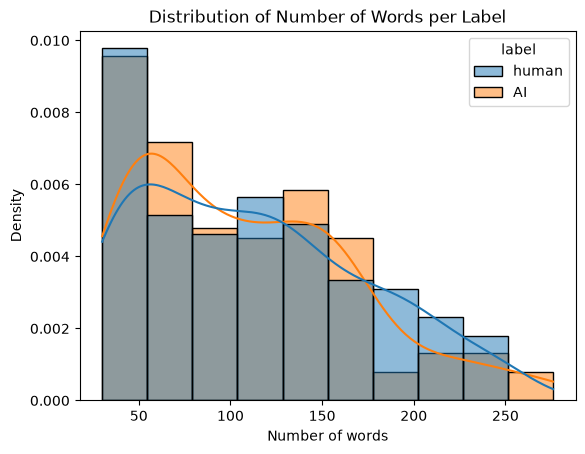

count    311.000000
mean     109.897106
std       60.307938
min       30.000000
25%       57.000000
50%      103.000000
75%      149.500000
max      276.000000
Name: n_words, dtype: float64


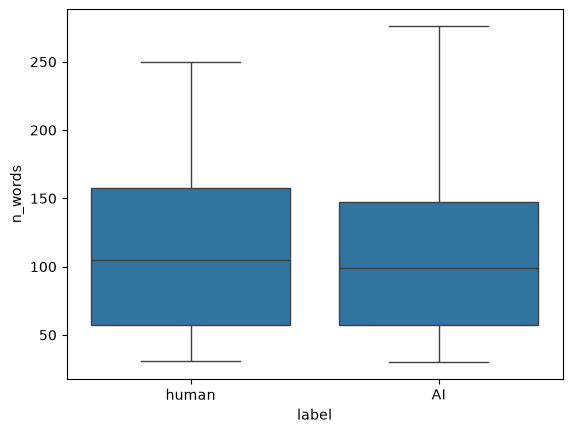

In [33]:
# Plotting the number of words per label 
sns.histplot(data=data_temp, x="n_words", hue="label", kde=True, stat="density", common_norm=False)
plt.title("Distribution of Number of Words per Label")
plt.xlabel("Number of words")
plt.show()

# Extremely short or extremely long transcripts
print(data_temp['n_words'].describe())
sns.boxplot(data=data_temp, x='label', y='n_words')
plt.show()